# TER - L'équation de Rayleigh-Stokes

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import plotly.graph_objects as go

## 1. Le modèle

La forme standard de l'équation pour une fonction de vitesse $u(x,t)$ est
$$\partial_tu(x,t)-\nu\Delta u(x,t)-\alpha\Delta\big(\partial_tu(x,t)\big) = f(x,t)$$
avec
- $\nu$ la viscosité cinématique du fluide, responsable de la diffusion classique,
- $\alpha$ le paramètre de Rayleigh-Stokes, lié aux propriétés viscoélastiques,
- $\Delta\big(\partial_t u(x,t)\big)$ terme dit de "dispersion régularisé" qui caractérise le comportement du fluide sous l'effet d'une accélération.

## 2. Approximation numérique préliminaire VF-DF

En appliquant un schéma d'Euler implicite pour le temps et une discrétisation par différences finies pour l'espace, l'équation devient
$$\frac{U^{n+1}-U^n}{\Delta t}-\nu \Delta_h U^{n+1} - \alpha \bigg(\frac{\Delta_h U^{n+1}-\Delta_h U^n}{\Delta t}\bigg) = F^{n+1}$$
En réorganisant les termes pour isoler l'inconnue au temps $n+1$, on obtient le système 
$$\big(I-(\nu \Delta t + \alpha)\Delta_h\big)U^{n+1} = (I - \alpha \Delta_h)U^n+\Delta t F^{n+1}$$
La matrice $\Delta_h$ est la matrice associée à l'opérateur approché du Laplacien 
$$L_hu(x,t) = \frac{u(x+h,t)-2u(x,t)+u(x-h,t)}{h^2}$$
elle est donc définie par
$$\Delta_h = \frac{1}{h^2}\begin{pmatrix}
-2 & 1 & 0 & \cdots & \cdots & 0 \\
1 & -2 & 1 & \ddots &  & \vdots \\
0 & 1 & -2 & 1 & \ddots & \vdots \\
\vdots & \ddots & \ddots & \ddots & \ddots & 0 \\
\vdots &  & \ddots & \ddots & \ddots & 1 \\
0 & \cdots & \cdots & 0 & 1 & -2 
\end{pmatrix}$$

In [3]:
# Affichage de la solution en 1D
def plot_sol(x, u):
    Nt2 = np.size(u[1,:])-1
    
    plt.figure()
    nn2 = 0
    for nn in range(5, 0, -1): #changer le premier nombre pour avoir plus ou moins de courbes
        nn2 += np.ceil((Nt2-1) / (2 ** nn))
        if nn2 > Nt2:
            break
        plt.plot(x, u[:, int(nn2)], 'b', linewidth=0.5)
    
    plt.plot(x, u[:, Nt2], color='black', label="Solution au temps final")
    plt.plot(x, u[:, 0], color='red', label="Donnée initiale")

    plt.xlabel("$x$")
    plt.ylabel("$u(t,x)$")
    plt.title("Equation de Rayleigh-Stokes 1D")
    plt.legend()
    plt.grid(True)
    plt.show()

### 2.1. Equation 1D avec conditions de Dirichlet homogène

In [4]:
# Paramètres
L = 1
nu = 0.1
alpha1 = 5*1e-4
alpha2 = 0
T = 1

# Données initiales
def u_0(x):
    return np.sin(np.pi * x)

def v_0(x):
    return np.exp(-(x - 5)**2)

In [5]:
def RS_1D_hom(Nx, Nt, T, L, nu, alpha, u_0):
    # Maillage espace
    deltax = L / Nx
    x = np.linspace(0, L, Nx + 1)

    # Maillage temps
    deltat = T / Nt
    t = []
    for i in range(Nt + 1):
        t.append(i * deltat)

    # Matrices associées
    Delta_h = np.zeros((Nx - 1, Nx - 1))
    I = np.eye(Nx - 1)

    for i in range(Nx - 1):
        for j in range(Nx - 1):
            if i == j:
                Delta_h[i, j] = - 2 / deltax**2
            elif j + 1 == i:
                Delta_h[i, j] = 1 / deltax**2
            elif j - 1 == i:
                Delta_h[i, j] = 1 / deltax**2

    A = np.linalg.inv(I - (nu * deltat + alpha) * Delta_h)
    B = I - alpha * Delta_h

    # Calcul de la solution
    u = np.zeros((Nx + 1, Nt + 1))
    
    # Solution à t=0
    for i in range(len(x)):
        u[i, 0] = u_0(x[i])

    # Solution à t=k
    for k in range(Nt):
        u[1:Nx, k + 1] = (A @ B) @ u[1:Nx, k]

    return u, x, t

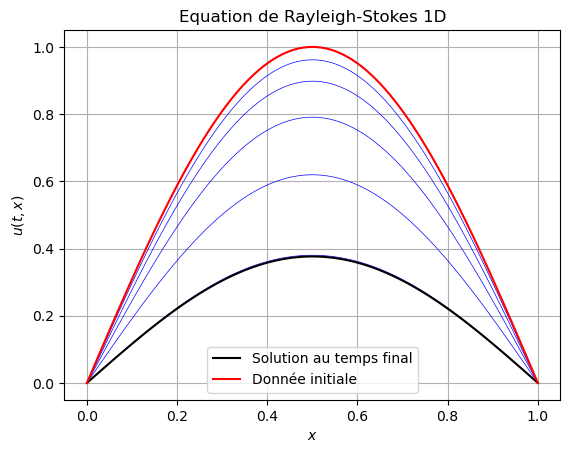

In [6]:
Nx = Nt = 100

u, x, t = RS_1D_hom(Nx, Nt, T, L, nu, alpha1, u_0)

plot_sol(x, u)

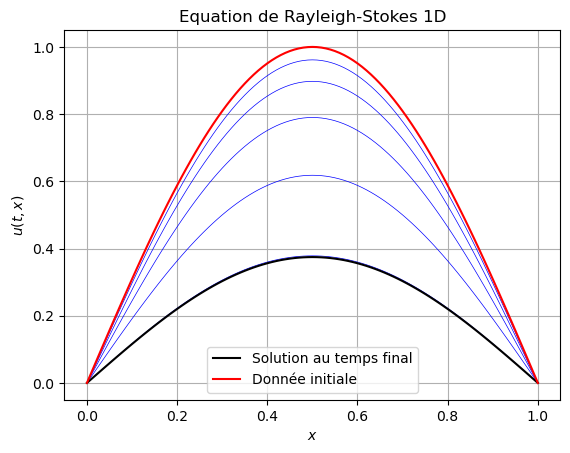

In [7]:
Nx = Nt = 100

u, x, t = RS_1D_hom(Nx, Nt, T, L, nu, alpha2, u_0)

plot_sol(x, u)

- On se place sur $[0,1]$ avec des conditions de Dirichlet homogène, on considère une donnée initiale constante égale à 0 correspondant à un fluide au repos et on prend $f\equiv -1$ comme second membre correspondant à l'application d'une force.

In [8]:
# Paramètres
L = 1 
nu = 0.01
alpha = 0.01
T = 3

# Données initiales
def u_0(x):
    return 0 * x  # Fluide au repos

In [9]:
def RS_1D(Nx, Nt, T, L, nu, alpha, u_0):
    # Maillage espace
    deltax = L / Nx
    x = np.linspace(0, L, Nx + 1)

    # Maillage temps
    deltat = T / Nt
    t = []
    for i in range(Nt + 1):
        t.append(i * deltat)

    # Matrices associées
    Delta_h = np.zeros((Nx - 1, Nx - 1))
    I = np.eye(Nx - 1)

    for i in range(Nx - 1):
        for j in range(Nx - 1):
            if i == j:
                Delta_h[i, j] = - 2 / deltax**2
            elif j + 1 == i:
                Delta_h[i, j] = 1 / deltax**2
            elif j - 1 == i:
                Delta_h[i, j] = 1 / deltax**2

    A = np.linalg.inv(I - (nu * deltat + alpha) * Delta_h)
    B = I - alpha * Delta_h

    # Vecteur second membre
    F = - np.ones(Nx - 1)

    # Calcul de la solution
    u = np.zeros((Nx + 1, Nt + 1))
    
    # Solution à t=0
    for i in range(len(x)):
        u[i, 0] = u_0(x[i])

    # Solution à t=k
    for k in range(Nt):
        u[1:Nx, k + 1] = (A @ B) @ u[1:Nx, k] + deltat * F

    return u, x, t

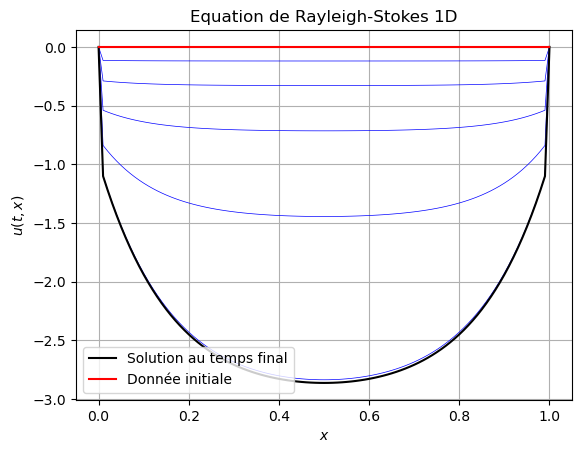

In [10]:
Nx = Nt = 100

u, x, t = RS_1D(Nx, Nt, T, L, nu, alpha, u_0)

plot_sol(x, u)

## 3. Comparaison des schémas

In [11]:
# Paramètres
L = 1 
nu = 1
alpha = 0.1
T = 1
l = np.pi**2 / (1 + alpha * np.pi**2)
Nx = 500
t_list = [10, 20, 40, 80, 160]

# Donnée initiale
def u_0(x):
    return np.sin(np.pi * x)

# Solution exacte
def u(t, x):
    return np.exp(- l * t) * np.sin(np.pi * x)

#### Euler implicite

In [12]:
def RS_1D_EI(Nx, Nt, T, L, nu, alpha, u_0):
    # Maillage espace
    deltax = L / Nx
    x = np.linspace(0, L, Nx + 1)

    # Maillage temps
    deltat = T / Nt
    t = []
    for i in range(Nt + 1):
        t.append(i * deltat)

    # Matrices associées
    Delta_h = np.zeros((Nx - 1, Nx - 1))
    I = np.eye(Nx - 1)

    for i in range(Nx - 1):
        for j in range(Nx - 1):
            if i == j:
                Delta_h[i, j] = - 2 / deltax**2
            elif j + 1 == i:
                Delta_h[i, j] = 1 / deltax**2
            elif j - 1 == i:
                Delta_h[i, j] = 1 / deltax**2

    A = np.linalg.inv(I - (nu * deltat + alpha) * Delta_h)
    B = I - alpha * Delta_h

    # Calcul de la solution
    u = np.zeros((Nx + 1, Nt + 1))
    
    # Solution à t=0
    for i in range(len(x)):
        u[i, 0] = u_0(x[i])

    # Solution à t=k
    for k in range(Nt):
        u[1:Nx, k + 1] = (A @ B) @ u[1:Nx, k]

    return u, x, t

#### Crank-Nicolson

In [13]:
def RS_1D_CN(Nx, Nt, T, L, nu, alpha, u_0):
    # Maillage espace
    deltax = L / Nx
    x = np.linspace(0, L, Nx + 1)

    # Maillage temps
    deltat = T / Nt
    t = []
    for i in range(Nt + 1):
        t.append(i * deltat)

    # Matrices associées
    Delta_h = np.zeros((Nx - 1, Nx - 1))
    I = np.eye(Nx - 1)

    for i in range(Nx - 1):
        for j in range(Nx - 1):
            if i == j:
                Delta_h[i, j] = - 2 / deltax**2
            elif j + 1 == i:
                Delta_h[i, j] = 1 / deltax**2
            elif j - 1 == i:
                Delta_h[i, j] = 1 / deltax**2

    A = np.linalg.inv(I - (nu * deltat * 0.5 + alpha) * Delta_h)
    B = I + (nu * deltat * 0.5 - alpha) * Delta_h

    # Calcul de la solution
    u = np.zeros((Nx + 1, Nt + 1))
    
    # Solution à t=0
    for i in range(len(x)):
        u[i, 0] = u_0(x[i])

    # Solution à t=k
    for k in range(Nt):
        u[1:Nx, k + 1] = (A @ B) @ u[1:Nx, k]

    return u, x, t

#### Comparaison

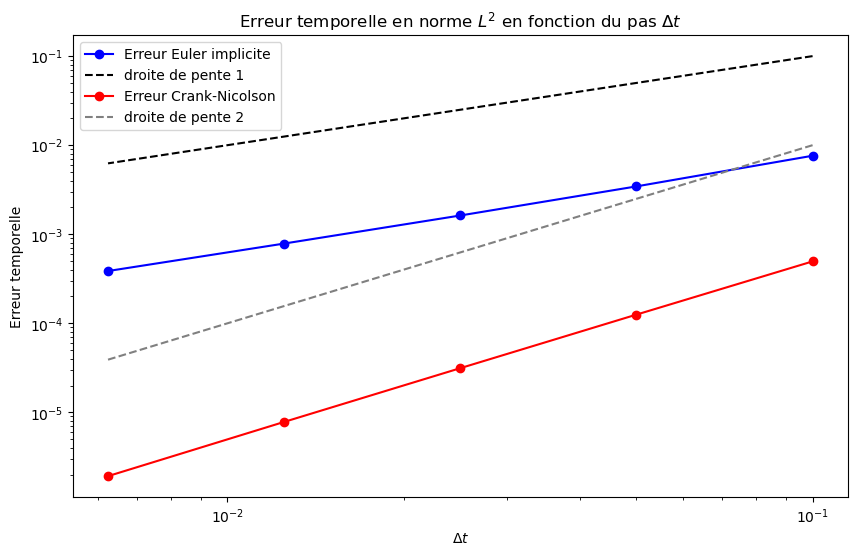

In [14]:
# Calcul des erreurs
E_EI = []
E_CN = []
T1 = []
T2 = []

for Nt in t_list :
    T1.append(T / Nt)
    T2.append((T / Nt)**2)

    # Erreur en norme L2 EI
    u_EI, x1, t1 = RS_1D_EI(Nx, Nt, T, L, nu, alpha, u_0)
    erreur_EI = np.abs(u(T, x1) - u_EI[:, -1])
    E_EI.append(np.sqrt((L / Nx) * np.sum(erreur_EI**2)))

    # Erreur en norme L2 CN
    u_CN, x2, t2 = RS_1D_CN(Nx, Nt, T, L, nu, alpha, u_0)
    erreur_CN = np.abs(u(T, x1) - u_CN[:, -1])
    E_CN.append(np.sqrt((L / Nx) * np.sum(erreur_CN**2)))

# Tracé des erreurs
plt.figure(figsize=(10, 6))
plt.loglog(T1, E_EI, '-o', color='blue', label='Erreur Euler implicite')
plt.loglog(T1, T1, '--', color='black', label='droite de pente 1')
plt.loglog(T1, E_CN, '-o', color='red', label='Erreur Crank-Nicolson')
plt.loglog(T1, T2, '--', color='grey', label='droite de pente 2')
plt.xlabel("$\Delta t$")
plt.ylabel("Erreur temporelle")
plt.legend()
plt.title("Erreur temporelle en norme $L^2$ en fonction du pas $\Delta t$")
plt.show()

## 4. Exemples

#### Stokes impulsif

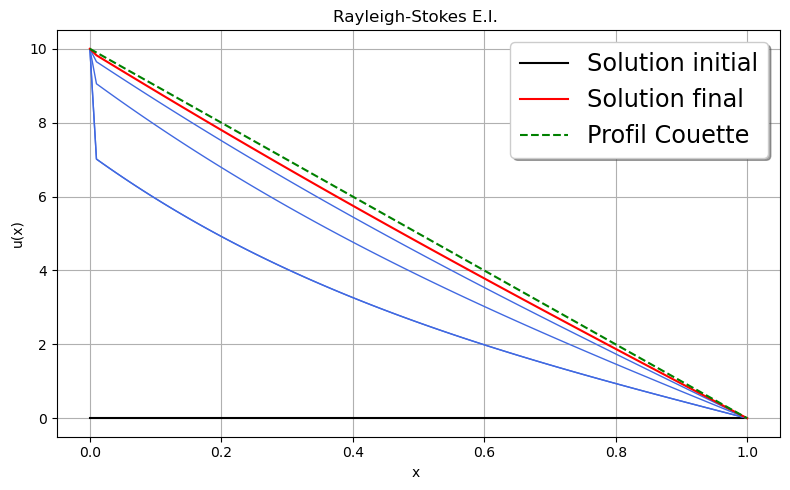

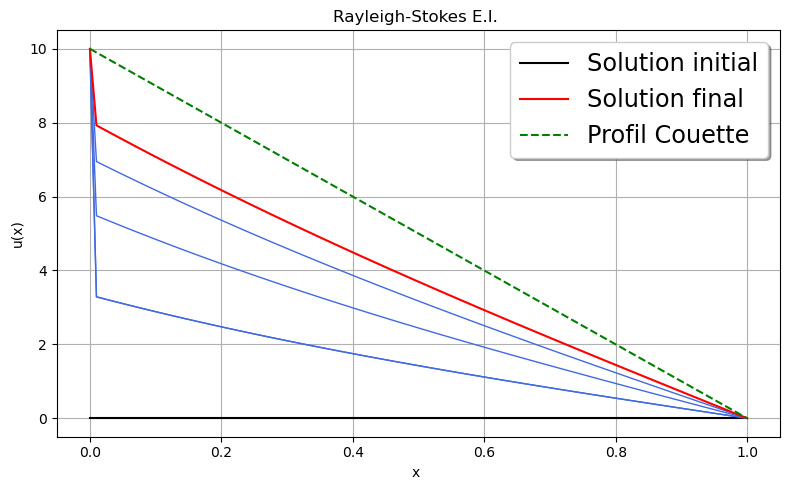

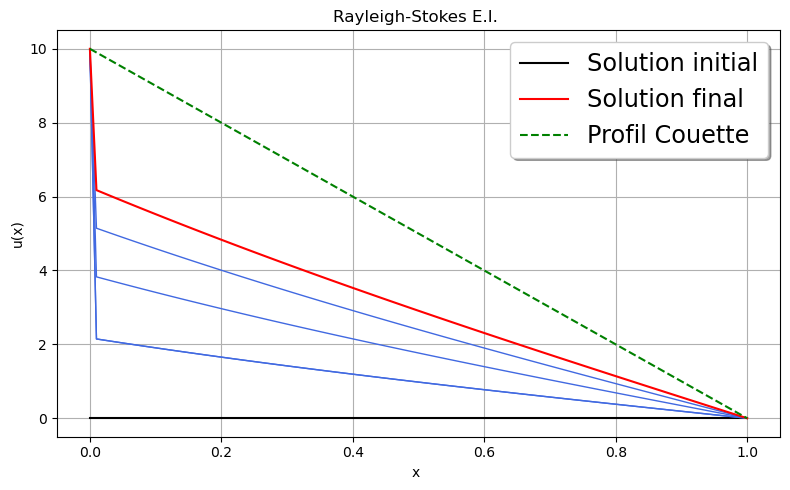

In [15]:
###################### Paramètres globaux ######################""
T = 3
v = 0.2
alpha = 0.4
L = 1
Nx = 500

U0 = 10

def u(x, t):
    return np.exp(-(v * np.pi**2 / (1 + alpha *np.pi**2)) * t) * np.sin(np.pi * x)

def u0(x):
    return np.sin(np.pi * x / L)

def f(x, t):
    return np.zeros_like(x)

# Relèvement / profil couette
def g(x):
    return U0 * (1 - x / L)

############# Euler Implicite ##################
def RS_EulerI_test4(T, Nt, alpha, v, plot=False):

    h = L / Nx
    x = np.linspace(0, L, Nx + 1)
    deltaT = T / Nt

    

    def resolv_U(deltaT, Nx, Nt, h):
        r = (v * deltaT + alpha) / h**2
        A = np.zeros((Nx - 1, Nx - 1))
        for i in range(Nx - 1):
            if i > 0:
                A[i, i - 1] = -r
            A[i, i] = 1 + 2 * r
            if i < Nx - 2:
                A[i, i + 1] = -r

        B = np.zeros((Nx - 1, Nx - 1))
        for i in range(Nx - 1):
            if i > 0:
                B[i, i - 1] = -alpha / h**2
            B[i, i] = 1 + 2 * alpha / h**2
            if i < Nx - 2:
                B[i, i + 1] = -alpha / h**2

        A_inv = np.linalg.inv(A)

        U = np.zeros((Nx + 1, Nt + 1))
        for i in range(Nx + 1):
            U[i, 0] = -g(x[i])

        M = A_inv @ B
        for n in range(Nt):
            U[1:Nx, n + 1] = M @ U[1:Nx, n] + A_inv @ (deltaT * f(x[1:Nx], (n + 1) * deltaT))

        return U

    U_tild = resolv_U(deltaT, Nx, Nt, h)

    U_solution = np.zeros_like(U_tild)
    for n in range(Nt + 1):
        U_solution[:, n] = U_tild[:, n] + g(x)


    if plot:
        plt.figure(figsize=(8, 5))
        ndim = U_solution.ndim
        plot_param = 4
        plot_size = plot_size = np.linspace(1, Nt - 1, plot_param, dtype=int)
        plt.plot(x, U_solution[:, 0], color="black", label="Solution initial")
        for i in plot_size:
            plt.plot(x, U_solution[:, int(i)], color="royalblue", linewidth=1)
        plt.plot(x, U_solution[:, -1], color="red", label="Solution final")
        plt.plot(x, g(x), linestyle='--', color="green", label="Profil Couette ")

        plt.xlabel("x ") # : position du fluide dans un tube de longeur 1
        plt.ylabel("u(x)") # : vitesse du fluide
        plt.title("Rayleigh-Stokes E.I. ")
        plt.legend(shadow=True, fontsize='xx-large')
        plt.grid()
        plt.tight_layout()
        plt.show()

    return x, U_solution
#################################################
T = 5
Nt= 4
v = 0.2
alpha=0.8
Nx = 100


alpha_tab = np.array([0.1, 0.5, 0.9])
dt = T / Nt
t_plot = np.linspace(0, T, Nt)
for alpha in alpha_tab:
    x, U_sol = RS_EulerI_test4(T, Nt, alpha, v, plot=True)

#### Régime forcé

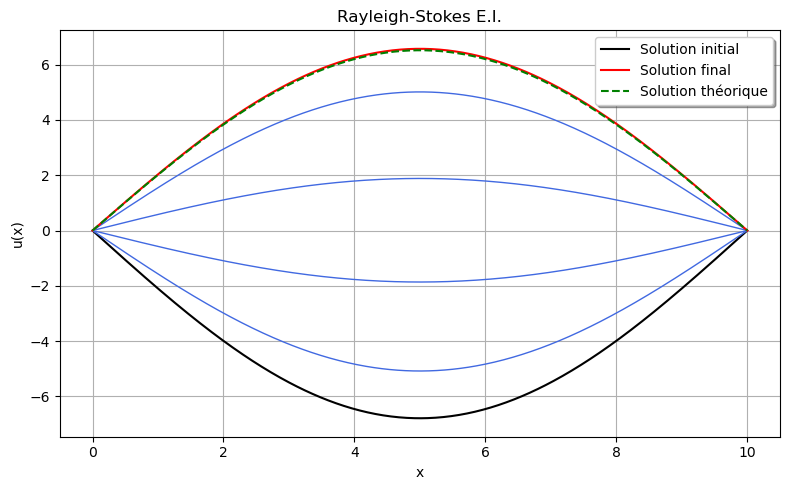

Amplitude max du fluide pour alpha = 0.5: 12.737697613620522


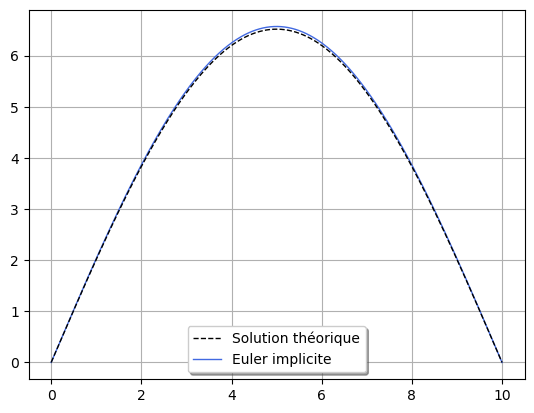

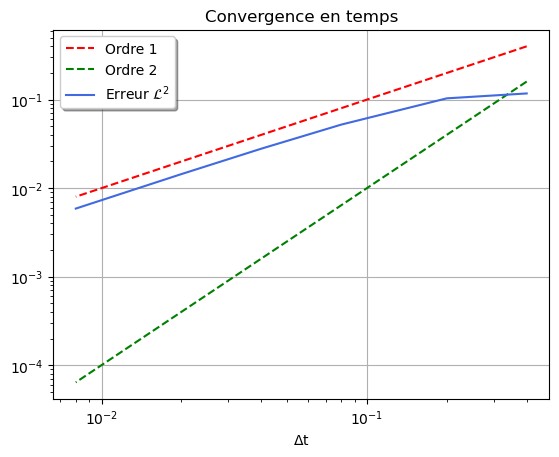

Pente EI : 0.793


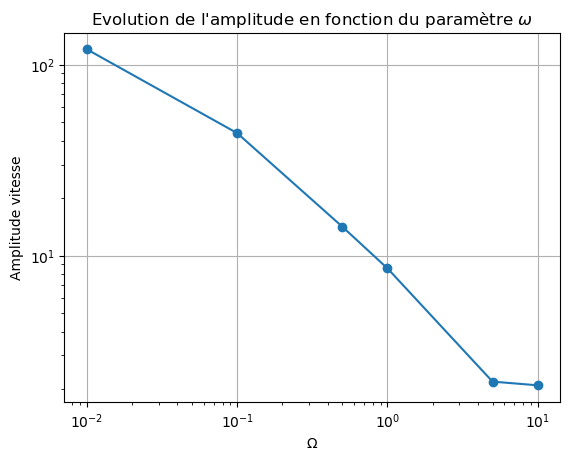

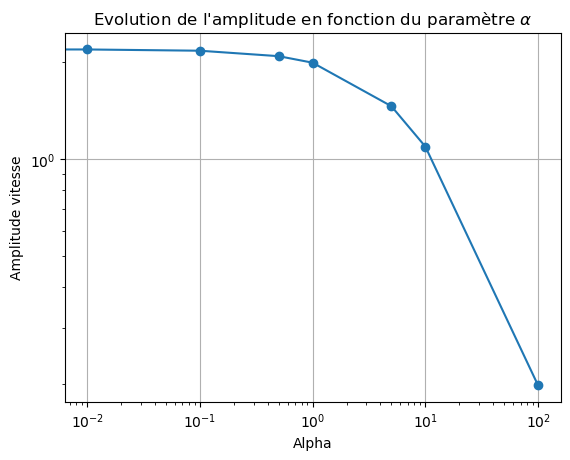

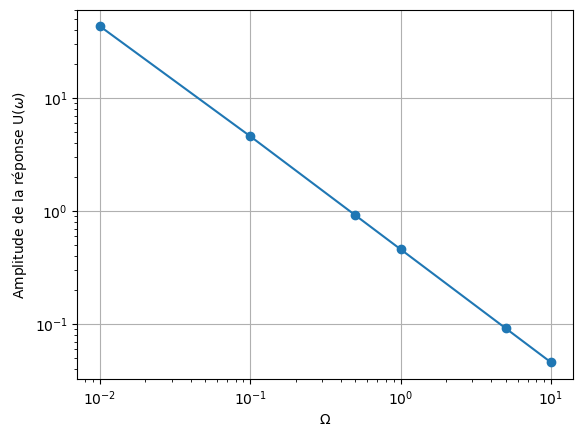

In [16]:
###################### Paramètres globaux ######################""
T = 4
v = 0.4
alpha = 0.5
L = 10 # résulta étrange pour L = 1 (amplitude numérique en fonction de omega)
Nx = 500
gamma = 0.7 # Pulsation, lettre c'est omega mais je me suis trompé au papier...
A = 5 # Amplitude
alpha1 = (np.pi / L)**2 # pareil sur les notes c'est lambda_1 et pas alpha_1 mais au papier j'ai pris les mauvaises notations...
phi = np.arctan(gamma * (1 + alpha * alpha1) /(v * alpha1))

def U(gamma):
    return A / np.sqrt((v * alpha1)**2 + gamma**2 * (1 + alpha * alpha1)**2)
def u(x, t, gamma):
    return U(gamma) * np.sin(gamma * t - phi) * np.sin( np.pi * x / L)

def u0(x, gamma):
    return U(gamma) * np.sin(-phi) * np.sin(np.pi * x / L)

def f(x, t):
    return A * np.sin(gamma * t) * np.sin(np.pi * x / L)

############# Euler Implicite ##################
def RS_EulerI(Nt, omega, alpha, plot=False):
    h = L / Nx
    x = np.linspace(0, L, Nx + 1)
    deltaT = T / Nt
    Amplitude = np.array([-np.inf,np.inf])

    def resolv_U(deltaT, Nx, Nt, h):
        r = (v * deltaT + alpha) / h**2
        A = np.zeros((Nx - 1, Nx - 1))
        for i in range(Nx - 1):
            if i > 0:
                A[i, i - 1] = -r
            A[i, i] = 1 + 2 * r
            if i < Nx - 2:
                A[i, i + 1] = -r

        B = np.zeros((Nx - 1, Nx - 1))
        for i in range(Nx - 1):
            if i > 0:
                B[i, i - 1] = -alpha / h**2
            B[i, i] = 1 + 2 * alpha / h**2
            if i < Nx - 2:
                B[i, i + 1] = -alpha / h**2

        A_inv = np.linalg.inv(A)

        U = np.zeros((Nx + 1, Nt + 1))
        for i in range(Nx + 1):
            U[i, 0] = u0(x[i],omega)

        M = A_inv @ B
        for n in range(Nt):
            U[1:Nx, n + 1] = M @ U[1:Nx, n] + A_inv @ (deltaT * f(x[1:Nx], (n + 1) * deltaT))            
            Amplitude[0] = max(Amplitude[0], np.max(U[:, n+1]))
            Amplitude[1] = min(Amplitude[1], np.min(U[:, n+1]))
        Ampli = np.abs(Amplitude[0] - Amplitude[1])

        return U, Ampli

    U, Ampli = resolv_U(deltaT, Nx, Nt, h)

    if plot:
        plt.figure(figsize=(8, 5))
        ndim = U.ndim
        plot_param = 4
        plot_size = np.floor(np.linspace(0 + ndim / 4, 11 - ndim / 4, plot_param + 2))[1:-1]
        plt.plot(x, U[:, 0], color="black", label="Solution initial")
        for i in plot_size:
            plt.plot(x, U[:, int(i)], color='royalblue', linewidth=1)
        plt.plot(x, U[:, -1], color="red", label="Solution final")
        plt.plot(x, u(x, T, gamma),linestyle='--', color="green", label="Solution théorique")

        plt.xlabel("x")
        plt.ylabel("u(x)")
        plt.title("Rayleigh-Stokes E.I.")
        plt.legend(shadow=True)
        plt.tight_layout()
        plt.grid()
        plt.show()

    return x, U[:, -1], Ampli

############# Erreur ####################################
def error_U(U_num, x):
    return np.sqrt((L/Nx) * np.sum(np.square(U_num - u(x, T, gamma))))

##### Plots individuels ##########
x, res_EI, Ampli = RS_EulerI(10, gamma, alpha, plot=True)
print(fr"Amplitude max du fluide pour alpha = {alpha}: {Ampli}")

plt.plot(x, u(x, T, gamma),  color="black", linestyle='--', zorder=3, linewidth=1, label="Solution théorique")
plt.plot(x, res_EI, color='royalblue', linewidth=1,  label="Euler implicite")
plt.grid()
plt.legend(shadow=True)
plt.show()

############ Convergence ##########################
Nt_liste = np.array([10, 20, 50, 100, 200, 500])
dt_liste = T / Nt_liste
err_EI = np.zeros(len(Nt_liste))


for i, nt in enumerate(Nt_liste):
    x, U_EI, Ampli= RS_EulerI(nt, gamma, alpha)
    err_EI[i] = error_U(U_EI, x)

plt.loglog(dt_liste, dt_liste**1, 'r--', label='Ordre 1')
plt.loglog(dt_liste, dt_liste**2, 'g--', label='Ordre 2')
plt.loglog(dt_liste, err_EI, color='royalblue', label=r'Erreur $\mathcal{L}^2$')
plt.xlabel(r"$\Delta$t")
plt.legend(shadow=True)
plt.title("Convergence en temps")
plt.grid()
plt.show()

for err, nom in [(err_EI, "EI")]:
    pente = np.polyfit(np.log(dt_liste), np.log(err), 1)[0]
    print(f"Pente {nom} : {np.round(pente, 3)}")

gamma_tab = np.array([0.01, 0.1, 0.5, 1, 5, 10])
alpha_tab = np.array([0,0.01, 0.1, 0.5, 1 , 5, 10, 100])
Ampli_tab = np.zeros_like(gamma_tab)
for i, gamma in enumerate(gamma_tab):
    x, res_EI, Ampli = RS_EulerI(10, gamma, alpha, plot=False)
    Ampli_tab[i] = Ampli
    # print(fr"Amplitude avec (alpha, omega) = ({alpha}, {gamma}): {np.round(Ampli, 2)}")
plt.loglog(gamma_tab, Ampli_tab, marker='o')
plt.xlabel(r"$\Omega$")
plt.ylabel("Amplitude vitesse")
plt.grid()
plt.title(r"Evolution de l'amplitude en fonction du paramètre $\omega$")
plt.show()

gamma = 10
Ampli_tab2 = np.zeros_like(alpha_tab)
for i, alpha in enumerate(alpha_tab):
    x, res_EI, Ampli = RS_EulerI(10, gamma, alpha, plot=False)
    Ampli_tab2[i] = Ampli
    # print(fr"Amplitude avec (alpha, omega) = ({alpha}, {gamma}): {np.round(Ampli, 2)}")
plt.loglog(alpha_tab, Ampli_tab2, marker='o')
plt.xlabel("Alpha")
plt.ylabel("Amplitude vitesse")
plt.grid()
plt.title(r"Evolution de l'amplitude en fonction du paramètre $\alpha$")
plt.show()

plt.figure()
plt.loglog(gamma_tab, U(gamma_tab), marker='o')
plt.xlabel(r'$\Omega$')
plt.ylabel(r'Amplitude de la réponse U($\omega$)')
plt.grid()
plt.show()

#### Indicatrice

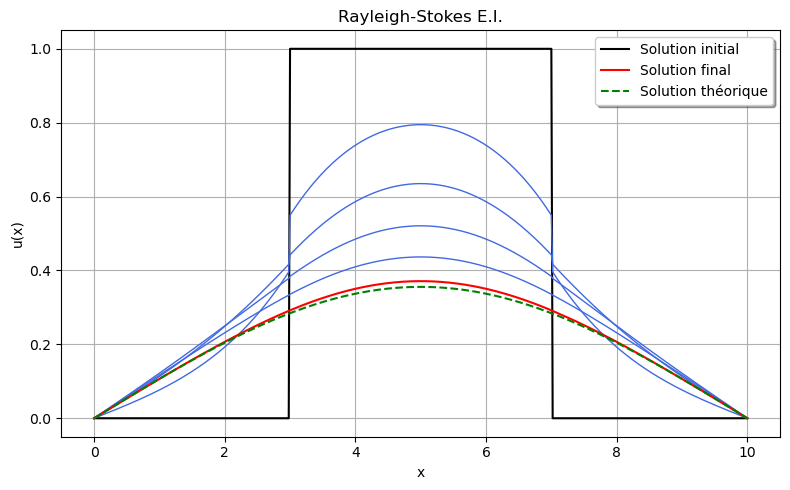

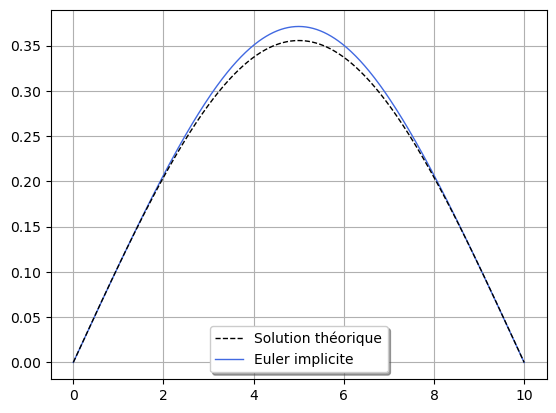

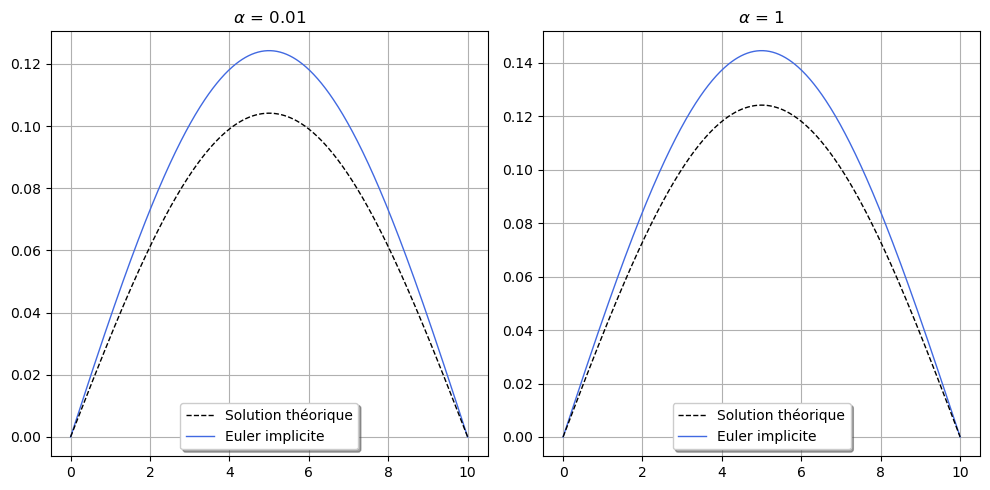

In [17]:
###################### Paramètres globaux ######################""
## Ce code est un copier coler du problème avec déphasage qui a été fait avant. Il y donc plusieurs parties en fonction d'un paramètre gamma qui ici ne sert à rien
T = 20
v = 0.4
alpha = 0.5
L = 10 
Nx = 500
gamma=1 # ici ne sert à rien (permet d'éviter un problème pour l'appel des fonctions)

def u(x, t):
    N_modes=200
    result = np.zeros_like(x)
    for k in range(1, N_modes + 1):
        lambda_k = (k * np.pi / L)**2
        coeff = (2 / L) * (L / (k * np.pi)) * ( np.cos(k * np.pi * 0.3) - np.cos(k * np.pi * 0.7))
        K = np.exp(-v * lambda_k / (1 + alpha * lambda_k) * t)
        result += coeff * K * np.sin(k * np.pi * x / L)
    return result

def u0(x,t):
    return np.where((x >= 0.3*L) & (x <= 0.7*L), 1.0, 0.0)

def f(x, t):
    return np.zeros_like(x)

############# Euler Implicite ##################
def RS_EulerI(Nt, omega, alpha, plot=False):
    h = L / Nx
    x = np.linspace(0, L, Nx + 1)
    deltaT = T / Nt
    Amplitude = np.array([-np.inf,np.inf])

    def resolv_U(deltaT, Nx, Nt, h):
        r = (v * deltaT + alpha) / h**2
        A = np.zeros((Nx - 1, Nx - 1))
        for i in range(Nx - 1):
            if i > 0:
                A[i, i - 1] = -r
            A[i, i] = 1 + 2 * r
            if i < Nx - 2:
                A[i, i + 1] = -r

        B = np.zeros((Nx - 1, Nx - 1))
        for i in range(Nx - 1):
            if i > 0:
                B[i, i - 1] = -alpha / h**2
            B[i, i] = 1 + 2 * alpha / h**2
            if i < Nx - 2:
                B[i, i + 1] = -alpha / h**2

        A_inv = np.linalg.inv(A)

        U = np.zeros((Nx + 1, Nt + 1))
        for i in range(Nx + 1):
            U[i, 0] = u0(x[i],omega)

        M = A_inv @ B
        for n in range(Nt):
            U[1:Nx, n + 1] = M @ U[1:Nx, n] + A_inv @ (deltaT * f(x[1:Nx], (n + 1) * deltaT))            
            Amplitude[0] = max(Amplitude[0], np.max(U[:, n+1]))
            Amplitude[1] = min(Amplitude[1], np.min(U[:, n+1]))
        Ampli = np.abs(Amplitude[0] - Amplitude[1])

        return U, Ampli

    U, Ampli = resolv_U(deltaT, Nx, Nt, h)

    if plot:
        plt.figure(figsize=(8, 5))
        ndim = U.ndim
        plot_param = 4
        plot_size = np.floor(np.linspace(0 + ndim / 4, 11 - ndim / 4, plot_param + 2))[1:-1]
        plt.plot(x, U[:, 0], color="black", label="Solution initial")
        for i in plot_size:
            plt.plot(x, U[:, int(i)], color='royalblue', linewidth=1)
        plt.plot(x, U[:, -1], color="red", label="Solution final")
        plt.plot(x, u(x, T),linestyle='--', color="green", label="Solution théorique")

        plt.xlabel("x")
        plt.ylabel("u(x)")
        plt.title("Rayleigh-Stokes E.I.")
        plt.legend(shadow=True)
        plt.tight_layout()
        plt.grid()
        plt.show()

    return x, U[:, -1], Ampli

############# Erreur ####################################
def error_U(U_num, x):
    return np.sqrt((L/Nx) * np.sum(np.square(U_num - u(x, T, gamma))))

##### Plots individuels ##########
x, res_EI, Ampli = RS_EulerI(10, gamma, alpha, plot=True)

plt.plot(x, u(x, T),  color="black", linestyle='--', zorder=3, linewidth=1, label="Solution théorique")
plt.plot(x, res_EI, color='royalblue', linewidth=1,  label="Euler implicite")
plt.grid()
plt.legend(shadow=True)
plt.show()


fig , (ax1, ax2) = plt.subplots(1,2, figsize=(10,5))
T=50
alpha=0.01
x, res_EI, Ampli = RS_EulerI(10, gamma, 0.01, plot=False)
ax1.plot(x, u(x, T),  color="black", linestyle='--', zorder=3, linewidth=1, label="Solution théorique")
ax1.plot(x, res_EI, color='royalblue', linewidth=1,  label="Euler implicite")
ax1.set_title(fr'$\alpha$ = {0.01}')
ax1.grid()
ax1.legend(shadow=True)

################
alpha=1
x , res_EI, Ampli = RS_EulerI(10, gamma, 1, plot=False)
ax2.plot(x, u(x, T),  color="black", linestyle='--', zorder=3, linewidth=1, label="Solution théorique")
ax2.plot(x, res_EI, color='royalblue', linewidth=1,  label="Euler implicite")
ax2.grid()
ax2.legend(shadow=True)
ax2.set_title(fr'$\alpha$ = {1}')
plt.tight_layout()
plt.show()

## 5. Galerkin discontinu

#### P0

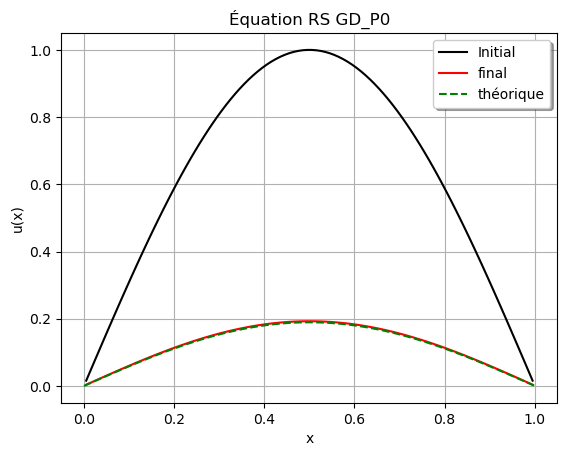

 Erreur L2 : 0.002


In [18]:
### Variable
L = 1
T = 5
v = 0.3
alpha = 0.8
Nx = 100
Nt = 100

h = L / Nx

def u(x, t):
    return np.exp(-(v * np.pi**2 / (1 + alpha *np.pi**2)) * t) * np.sin(np.pi * x)
    
###
def Resolution_RS_P0(Nt, N_mailles):

    def f(x,t): 
        return np.zeros_like(x)

    def u0(x): #solution initiale
        return np.sin(np.pi * x )

    maillage = np.linspace(0, L, N_mailles + 1)
    
    X = np.array([(maillage[i] + maillage[i+1]) / 2 for i in range(N_mailles)])
        
    #cond initiale
    U = np.zeros((N_mailles, Nt + 1))
    U[:, 0] = u0(X)
    ###############
    deltaT = T / Nt

    r = (v * deltaT + alpha) / h**2
    A = np.zeros((N_mailles, N_mailles))
    for i in range(N_mailles):
        if i > 0:
            A[i, i - 1] = -r
        A[i, i] = 1 + 2 * r
        if i < N_mailles - 1:
            A[i, i + 1] = -r
 
    B = np.zeros((N_mailles, N_mailles))
    for i in range(N_mailles):
        if i > 0:
            B[i, i - 1] = -alpha / h**2
        B[i, i] = 1 + 2 * alpha / h**2
        if i < N_mailles - 1:
            B[i, i + 1] = -alpha / h**2

    A_inv = np.linalg.inv(A)

    M = A_inv @ B
    for n in range(Nt):
        U[:, n + 1] = M @ U[:, n] + A_inv @ (deltaT * f(X, (n + 1) * deltaT))

    errL2 = np.sqrt(h * np.sum(np.square(U[:, -1] - u(X, T))))
    return X, U, errL2


X , U, err = Resolution_RS_P0(100, 100)
x = np.linspace(0,1, 100)
plt.figure()
plt.plot(X, U[:,0], label="Initial", color='black')
plt.plot(X, U[:, -1], label="final", color='red')
plt.plot(x, u(x, T), label='théorique', color='green', linestyle='--')
plt.legend(shadow=True)
plt.title("Équation RS GD_P0")
plt.xlabel('x')
plt.ylabel('u(x)')
plt.grid()
plt.show()
print(f" Erreur L2 : {np.round(err, 3)}")